In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

In [2]:
# Load the dataset
data = load_breast_cancer(as_frame=True)

X = data.data

# Labels: 0 -> Malignant, 1 -> Benign
y = data.target

print("Dataset dimensions:", X.shape)

print("Top 5 instances:")
display(X.head())

print("\nDiagnosis distribution:")
print(
    y.value_counts()
     .rename(index={0: "Malignant", 1: "Benign"})
)

Dataset dimensions: (569, 30)
Top 5 instances:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Diagnosis distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [3]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nDimensions after standardization:", X_scaled.shape)


Dimensions after standardization: (569, 30)


In [4]:
# Apply LDA for dimensionality reduction
lda = LinearDiscriminantAnalysis(n_components=1)

X_lda = lda.fit_transform(X_scaled, y)

print("Original dimensions:", X_scaled.shape)
print("Dimensions after LDA:", X_lda.shape)

print("\nNumber of discriminant components:", X_lda.shape[1])

Original dimensions: (569, 30)
Dimensions after LDA: (569, 1)

Number of discriminant components: 1


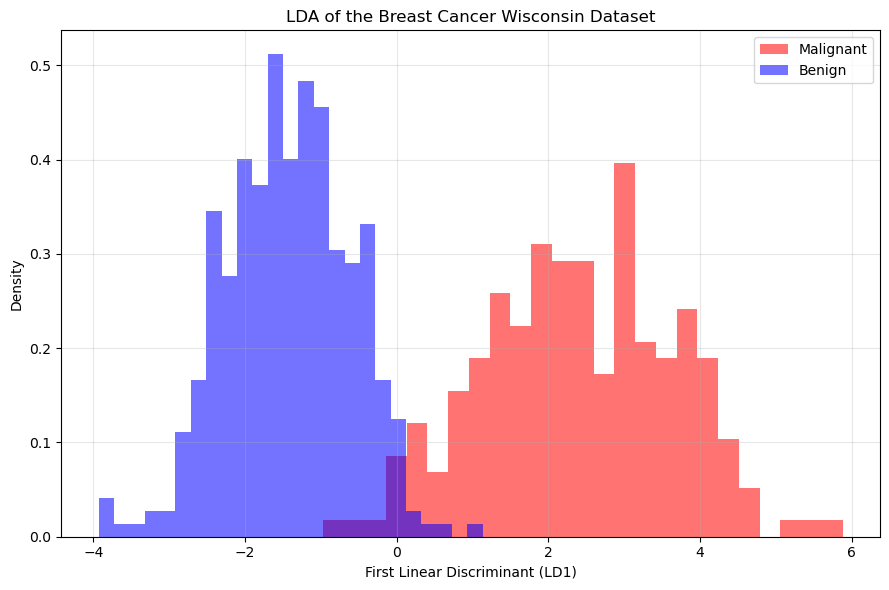

In [5]:
# Plot the distribution of the first discriminant component
plt.figure(figsize=(9, 6))

colors = {0: "red", 1: "blue"}
labels = {0: "Malignant", 1: "Benign"}

for diagnosis in [0, 1]:
    mask = (y.to_numpy() == diagnosis)

    plt.hist(
        X_lda[mask, 0],
        bins=25,
        alpha=0.55,
        color=colors[diagnosis],
        label=labels[diagnosis],
        density=True
    )

plt.xlabel("First Linear Discriminant (LD1)")
plt.ylabel("Density")
plt.title("LDA of the Breast Cancer Wisconsin Dataset")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:/Users/ak221/Downloads/lda_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

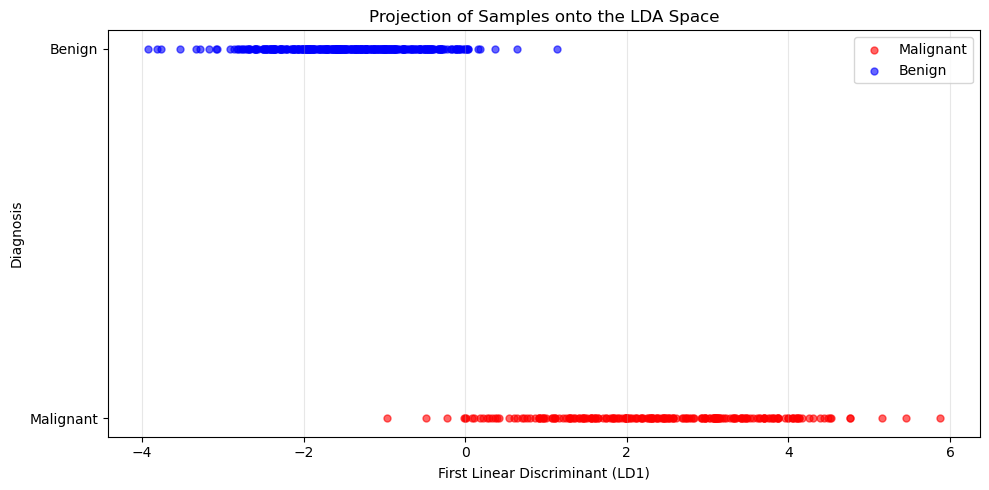

In [6]:
# Plot individual samples in the one-dimensional LDA space
plt.figure(figsize=(10, 5))

colors = {0: "red", 1: "blue"}
labels = {0: "Malignant", 1: "Benign"}
y_positions = {0: 0, 1: 1}

for diagnosis in [0, 1]:
    mask = (y.to_numpy() == diagnosis)

    plt.scatter(
        X_lda[mask, 0],
        np.full(mask.sum(), y_positions[diagnosis]),
        c=colors[diagnosis],
        label=labels[diagnosis],
        alpha=0.6,
        s=25
    )

plt.yticks([0, 1], ["Malignant", "Benign"])
plt.xlabel("First Linear Discriminant (LD1)")
plt.ylabel("Diagnosis")
plt.title("Projection of Samples onto the LDA Space")
plt.legend()
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:/Users/ak221/Downloads/lda_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Create a table with the LDA-transformed data
lda_table = pd.DataFrame({
    "LD1": X_lda[:, 0],
    "Diagnosis": y.map({0: "Malignant", 1: "Benign"}).to_numpy()
})

print("First 10 samples in the LDA space:")
display(lda_table.head(10).round(4))

First 10 samples in the LDA space:


,LD1,Diagnosis
0,3.3239,Malignant
1,2.3191,Malignant
2,3.7474,Malignant
3,4.0485,Malignant
4,2.2812,Malignant
5,1.6115,Malignant
6,2.3565,Malignant
7,1.2812,Malignant
8,1.6083,Malignant
9,3.8627,Malignant


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set dimensions:", X_train.shape)
print("Test set dimensions:", X_test.shape)

# Standardization + LDA classifier
lda_classifier = make_pipeline(
    StandardScaler(),
    LinearDiscriminantAnalysis()
)

# Train 
lda_classifier.fit(X_train, y_train)

# Predict the test samples
y_pred = lda_classifier.predict(X_test)

print("\nModel training completed.")

Training set dimensions: (455, 30)
Test set dimensions: (114, 30)

Model training completed.


In [9]:
#Classification metrics
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\nClassification report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        digits=4,
        zero_division=0
    )
)

Accuracy: 0.9561

Classification report:
              precision    recall  f1-score   support

   Malignant     0.9744    0.9048    0.9383        42
      Benign     0.9467    0.9861    0.9660        72

    accuracy                         0.9561       114
   macro avg     0.9605    0.9454    0.9521       114
weighted avg     0.9569    0.9561    0.9558       114



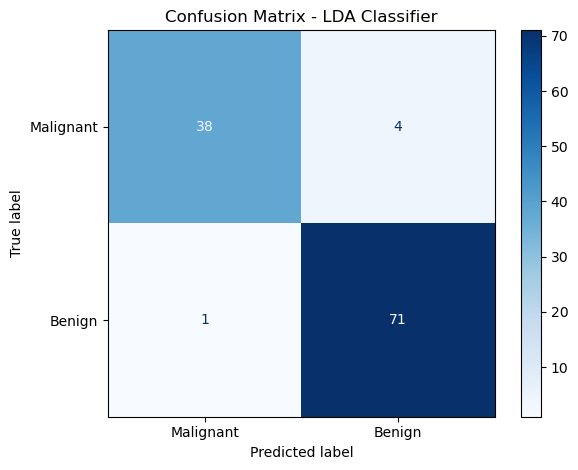

In [10]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - LDA Classifier")
plt.tight_layout()

plt.savefig(
    r"C:/Users/ak221/Downloads/lda_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()